In [40]:
import os

print("Notebook working directory:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Notebook working directory:
/home/hafi

Files in this folder:
['.jupyter', '.eclipse', '.bash_history', '.local', '.bashrc', '.config', '.continuum', '.p2', '....odt', 'Anaconda3-2024.10-1-Linux-x86_64.sh', '.npm', '.sudo_as_admin_successful', '.anaconda', '.mysql_history', 'Pictures', 'Desktop', '.gnupg', '.ipython', '.java', 'Untitled1.ipynb', '.cache', 'FN.pdf', '.dotnet', '.swt', '.profile', 'Hidden_Electricity_Bill.ipynb', 'PyCharmMiscProject', 'gitprojects', '.ssh', '.codex', 'anaconda_projects', '.vscode', 'anaconda3', '.ipynb_checkpoints', 'Downloads', 'snap', 'git', '.condarc', '.conda', 'gitprojects.pub', '.thunderbird', 'movies', 'Documents', 'netflix', '.mozilla', '.nvm', '.pki', '.sqlite_history', 'Untitled2.ipynb', '.wget-hsts', '.virtual_documents', '.zoom', 'Public', 'Untitled.ipynb', 'electricity_bill.ipynb', '.gitconfig', '.m2', 'extract', '.streamlit', 'FN,\\.pdf', 'usi']


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
# Household appliance data
data = {
    "appliance": [
        "Ceiling Fan",
        "LED Bulbs",
        "Refrigerator",
        "Air Conditioner",
        "Television",
        "Washing Machine",
        "Laptop",
        "Water Heater"
    ],
     # Average effective power in watts
    "power_w": [75, 9, 60, 800, 100, 500, 65, 2000],

    # Number of appliances
    "quantity": [3, 5, 1, 1, 1, 1, 2, 1],

    # Average hours of use per day
    "hours_per_day": [12, 6, 24, 7, 4, 0.5, 5, 0.5],

    # Assumed avoidable usage hours per day
    "avoidable_hours": [2, 1, 0, 2, 1, 0, 0.5, 0.1]
}

df = pd.DataFrame(data)

df

,appliance,power_w,quantity,hours_per_day,avoidable_hours
0,Ceiling Fan,75,3,12.0,2.0
1,LED Bulbs,9,5,6.0,1.0
2,Refrigerator,60,1,24.0,0.0
3,Air Conditioner,800,1,7.0,2.0
4,Television,100,1,4.0,1.0
5,Washing Machine,500,1,0.5,0.0
6,Laptop,65,2,5.0,0.5
7,Water Heater,2000,1,0.5,0.1


In [31]:
days = 30
rate_per_unit= 7 #in rupees

#calculate monthly electricity units
df["monthly_units"] = (df["power_w"]*df["quantity"]*df["hours_per_day"]*days/1000)

#calculate the monthly cost for that units
df["monthly_cost"] = ( df["monthly_units"] * rate_per_unit)

#display
print(df[["appliance","monthly_units","monthly_cost"]].round(2))

         appliance  monthly_units  monthly_cost
0      Ceiling Fan           81.0         567.0
1        LED Bulbs            8.1          56.7
2     Refrigerator           43.2         302.4
3  Air Conditioner          168.0        1176.0
4       Television           12.0          84.0
5  Washing Machine            7.5          52.5
6           Laptop           19.5         136.5
7     Water Heater           30.0         210.0


In [32]:
#sort the appliances by electrycity consumption

top_consumer = df.sort_values(by="monthly_units",ascending=False)
print(top_consumer[["appliance","monthly_units","monthly_cost"]])

         appliance  monthly_units  monthly_cost
3  Air Conditioner          168.0        1176.0
0      Ceiling Fan           81.0         567.0
2     Refrigerator           43.2         302.4
7     Water Heater           30.0         210.0
6           Laptop           19.5         136.5
4       Television           12.0          84.0
1        LED Bulbs            8.1          56.7
5  Washing Machine            7.5          52.5


In [33]:
#display the highest consumer

highest = top_consumer.iloc[0]

print("Highest electricity consumer is :")
print(highest["appliance"])

print("The monthly units consumed is: ", round(highest["monthly_units"],2))
print("The monthly cost is: ", round(highest["monthly_cost"],2))

Highest electricity consumer is :
Air Conditioner
The monthly units consumed is:  168.0
The monthly cost is:  1176.0


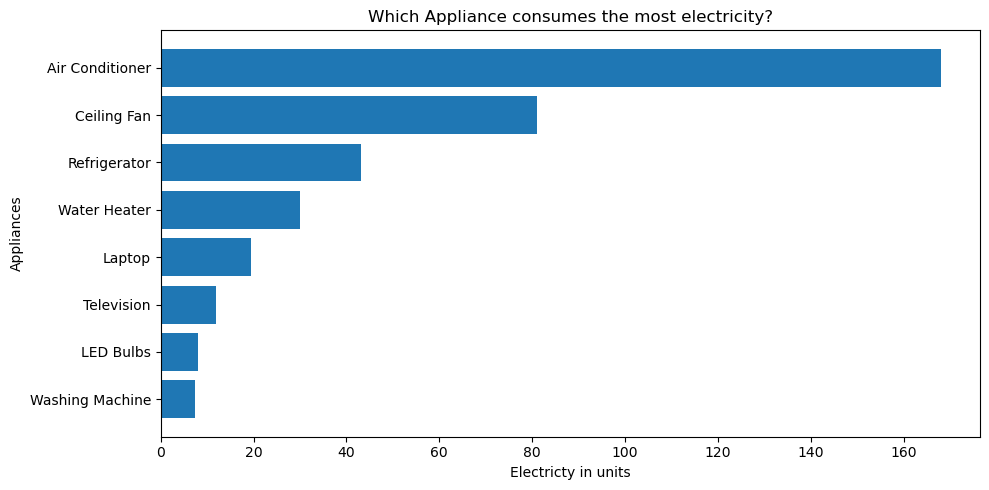

In [34]:
plt.figure(figsize=(10,5))

plt.barh(top_consumer["appliance"],top_consumer["monthly_units"])

plt.xlabel("Electricty in units")
plt.ylabel("Appliances")
plt.title("Which Appliance consumes the most electricity?")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [35]:
#calculate potential saving units

df["potential_unit"] =(df["power_w"]*df["quantity"]*df["avoidable_hours"]*days/1000)

df["potential_saving"] = ( df["potential_unit"] * rate_per_unit)

total_saving = df["potential_saving"].sum()

print("Potential monthly saving :", round(total_saving,2))

Potential monthly saving : 516.6


In [36]:
#show appliance wise saving

print(df[["appliance","potential_unit","potential_saving"]].round(2))


         appliance  potential_unit  potential_saving
0      Ceiling Fan           13.50             94.50
1        LED Bulbs            1.35              9.45
2     Refrigerator            0.00              0.00
3  Air Conditioner           48.00            336.00
4       Television            3.00             21.00
5  Washing Machine            0.00              0.00
6           Laptop            1.95             13.65
7     Water Heater            6.00             42.00


In [37]:
total_current_cost = df["monthly_cost"].sum()
potential_saving_cost = df["potential_saving"].sum()
estimated_new_cost = total_current_cost- potential_saving_cost
print("Current Bill : ", round(total_current_cost,2))
print("Potential saving cost : ", round(potential_saving_cost,2))
print("Revised estimated bill :", round(estimated_new_cost,2))

Current Bill :  2585.1
Potential saving cost :  516.6
Revised estimated bill : 2068.5


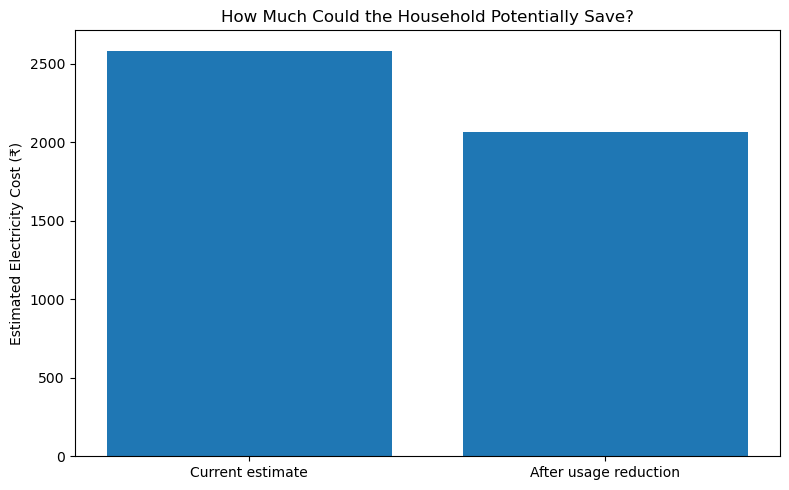

In [38]:
# Visual comparison
labels = ["Current estimate", "After usage reduction"]

values = [total_current_cost, estimated_new_cost]

plt.figure(figsize=(8, 5))

plt.bar(labels, values)

plt.ylabel("Estimated Electricity Cost (₹)")
plt.title("How Much Could the Household Potentially Save?")

plt.tight_layout()
plt.show()


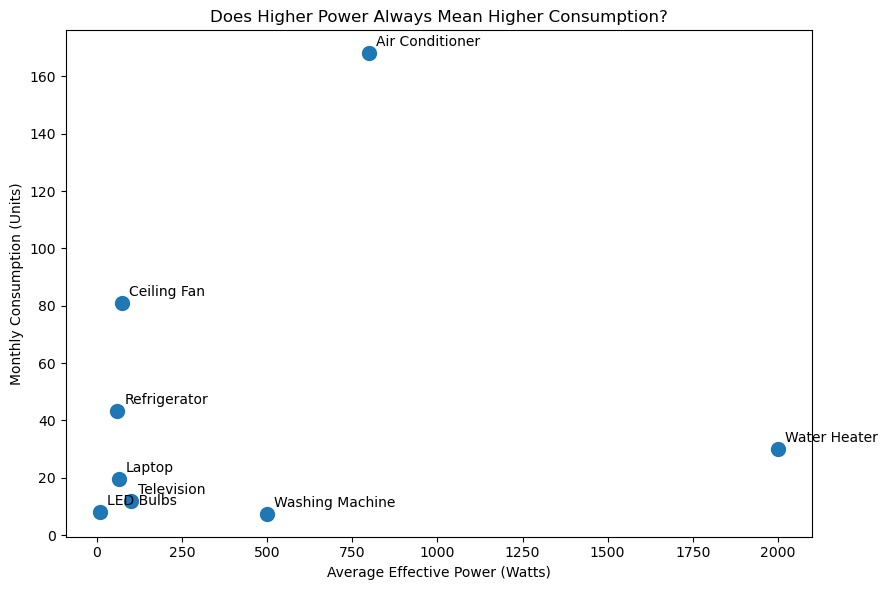

In [39]:
#Is the appliance with the highest wattage necessarily the biggest monthly expense?

# Compare power rating against monthly consumption

plt.figure(figsize=(9, 6))

plt.scatter(
    df["power_w"],
    df["monthly_units"],
    s=100
)

for i, row in df.iterrows():
    plt.annotate(
        row["appliance"],
        (row["power_w"], row["monthly_units"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Average Effective Power (Watts)")
plt.ylabel("Monthly Consumption (Units)")

plt.title("Does Higher Power Always Mean Higher Consumption?")

plt.tight_layout()
plt.show()
